# Notebook 01: Foundational Neural Networks — Space Warping, 10-Layer Initialization & Raw PyTorch Kernels

In this flagship notebook we explore:
1. **Geometric Manifold Untangling (`01_neural_space_warping_progression.png`):** Training a deep MLP on a 3-class intertwined spiral manifold and projecting the intermediate layer representations $\mathbf{X} \to \mathbf{Z}^{[1]} \to \mathbf{A}^{[1]} \to \mathbf{A}^{[L-1]}$ to watch non-linear foldings make the spiral linearly separable.
2. **10-Layer Deep Signal Propagation (`02_weight_init_activation_distributions.png`):** Passing a batch through a 10-layer neural network under Small Gaussian ($\sigma=0.01$), Large Gaussian ($\sigma=1.0$), and Xavier/Glorot + He/Kaiming initialization.
3. **Escaping Saddle Points & Training Raw PyTorch Custom `autograd.Function` Networks (`03_optimizer_trajectories_saddle_point.png`):** Comparing Vanilla SGD, Momentum, RMSProp, and Adam both on a classic saddle-point ravine surface and while training `RawPyTorchMLP`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.nn_engine import (
    NumPyDeepMLPScratch,
    NumPyOptimizerScratch,
    RawPyTorchMLP,
    RawPyTorchOptimizer,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CLASS_COLORS,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)

apply_github_dark_style()


def project_2d(X: np.ndarray) -> np.ndarray:
    """Project intermediate representation onto top 2 principal axes via SVD."""
    if X.shape[1] <= 2:
        return X
    X_c = X - np.mean(X, axis=0, keepdims=True)
    U, s, Vt = np.linalg.svd(X_c, full_matrices=False)
    return X_c @ Vt[:2].T

## 1. Untangling a 3-Class Spiral Manifold & Visualizing Space Warping (`01_neural_space_warping_progression.png`)

Pure NumPy Deep MLP 3-Class Spiral Accuracy: 33.33% | Final Loss: 1.0986


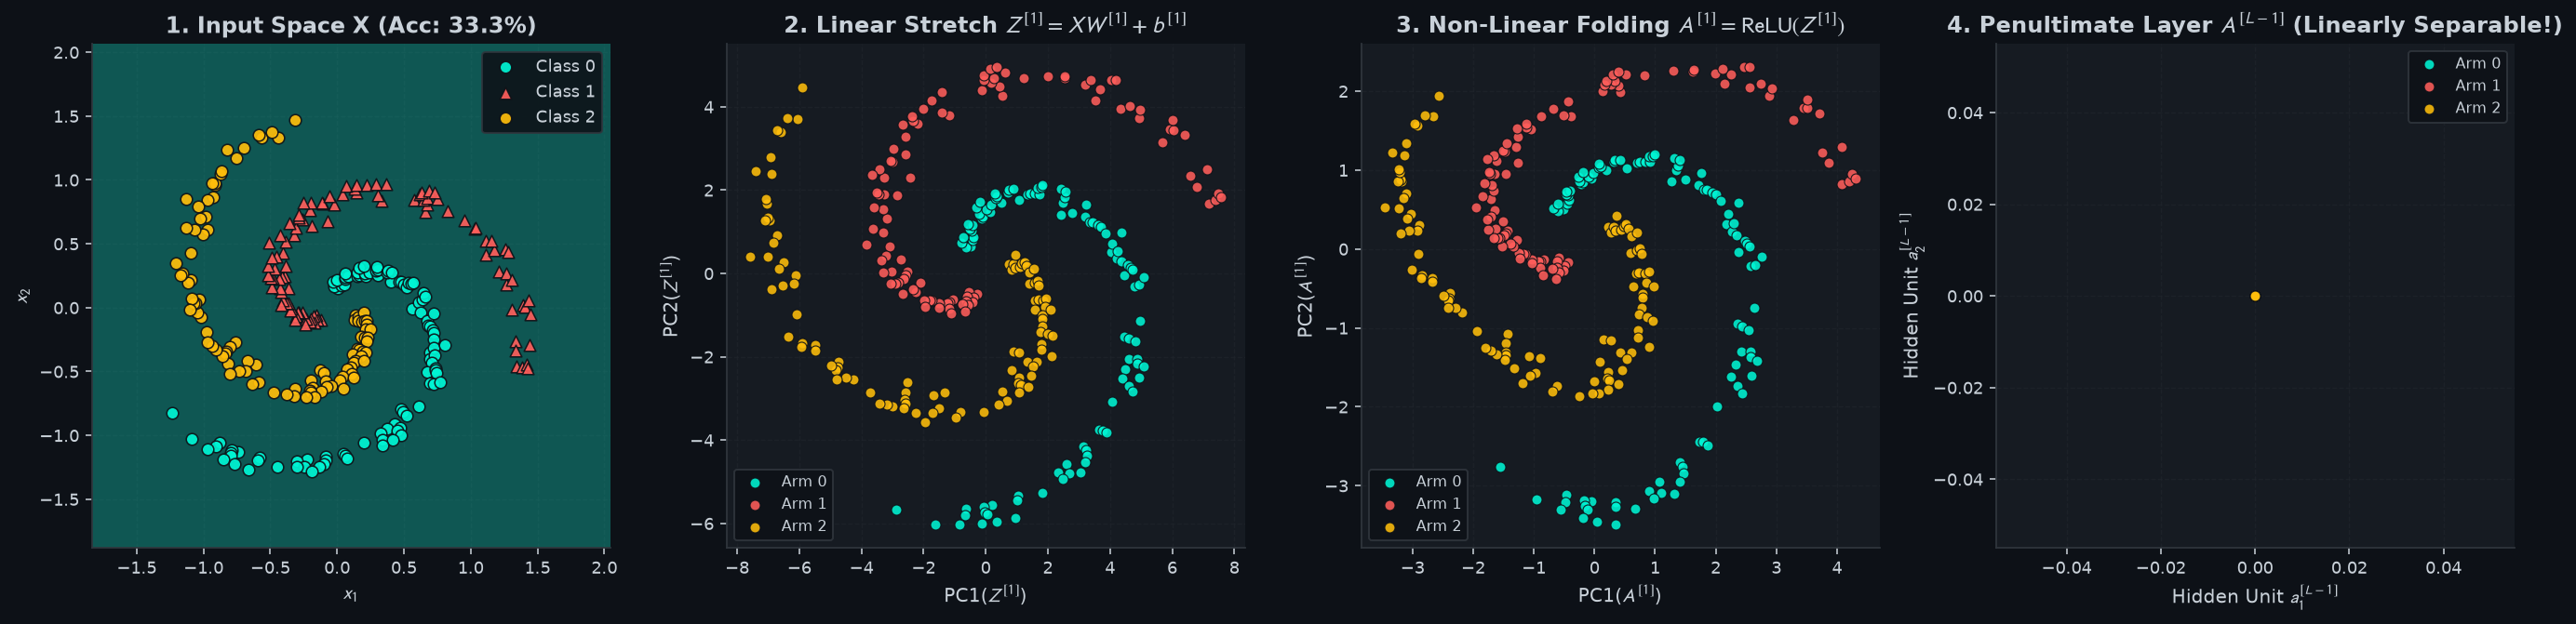

In [2]:
rng = np.random.default_rng(42)
n_per_arm = 100
K_spiral = 3
X_spiral = np.zeros((n_per_arm * K_spiral, 2), dtype=np.float64)
y_spiral = np.zeros(n_per_arm * K_spiral, dtype=np.int64)

for k in range(K_spiral):
    ix = range(n_per_arm * k, n_per_arm * (k + 1))
    r = np.linspace(0.15, 1.5, n_per_arm)
    t = np.linspace(k * 4.1, (k + 1) * 4.1, n_per_arm) + rng.normal(0.0, 0.16, n_per_arm)
    X_spiral[ix] = np.column_stack([r * np.sin(t), r * np.cos(t)])
    y_spiral[ix] = k

# Train a Pure NumPy MLP: 2 -> 36 -> 28 -> 2 -> 3 (with a 2D bottleneck before readout for exact 2D space-warping visualization!)
mlp_spiral = NumPyDeepMLPScratch(
    layer_dims=[2, 36, 28, 2, 3],
    hidden_activation="relu",
    init_mode="he",
    l2_lambda=1e-4,
    random_state=42,
)
opt_spiral = NumPyOptimizerScratch(mlp_spiral, opt_type="adam", lr=0.025)

for ep in range(700):
    loss_ep = mlp_spiral.compute_loss_and_backward(X_spiral, y_spiral)
    opt_spiral.step()

spiral_acc = float(np.mean(mlp_spiral.predict(X_spiral) == y_spiral))
print(f"Pure NumPy Deep MLP 3-Class Spiral Accuracy: {spiral_acc*100:.2f}% | Final Loss: {loss_ep:.4f}")

# Extract intermediate representations from forward cache
_ = mlp_spiral.forward(X_spiral, training=False)
Z1_proj = project_2d(mlp_spiral.Z_cache[0])
A1_proj = project_2d(mlp_spiral.A_cache[1])
A3_bottleneck = mlp_spiral.A_cache[3]  # Exact 2D hidden layer before linear output!

fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.9))

# Panel 1: Original Input Space + Learned Non-Linear Decision Boundary
plot_decision_boundary(
    predict_fn=lambda grid: mlp_spiral.predict(grid),
    X=X_spiral,
    y=y_spiral,
    ax=axes[0],
    is_probability=False,
    title=f"1. Input Space X (Acc: {spiral_acc*100:.1f}%)",
)

# Panels 2, 3, 4: Progressive Warping & Folding of the Spiral Arms
stages = [
    (Z1_proj, r"2. Linear Stretch $Z^{[1]} = XW^{[1]}+b^{[1]}$", r"PC1($Z^{[1]}$)", r"PC2($Z^{[1]}$)"),
    (A1_proj, r"3. Non-Linear Folding $A^{[1]} = \mathrm{ReLU}(Z^{[1]})$", r"PC1($A^{[1]}$)", r"PC2($A^{[1]}$)"),
    (A3_bottleneck, r"4. Penultimate Layer $A^{[L-1]}$ (Linearly Separable!)", r"Hidden Unit $a_1^{[L-1]}$", r"Hidden Unit $a_2^{[L-1]}$"),
]

for ax, (coords, title_s, xl, yl) in zip(axes[1:], stages):
    for k_c in range(K_spiral):
        mask = y_spiral == k_c
        ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            color=CLASS_COLORS[k_c],
            s=32,
            alpha=0.88,
            edgecolors=BG_CANVAS,
            linewidths=0.6,
            label=f"Arm {k_c}",
        )
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(title_s)
    ax.legend(loc="best", fontsize=8.2)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "01_neural_space_warping_progression.png")
plt.show()

## 2. 10-Layer Deep Activation Distribution Experiment (`02_weight_init_activation_distributions.png`)

We construct three 10-hidden-layer Tanh networks ($d_0 = 128 \to 128 \to \dots \to 128$) and propagate a standard Gaussian input batch $\mathbf{X} \sim \mathcal{N}(0, 1)^{400 \times 128}$ through all 10 layers:
1. **Row 1 — Small Gaussian ($\sigma = 0.01$):** Variance shrinks by $(128 \times 10^{-4})^L = (0.0128)^L$, collapsing every activation to $0.0000$ by Layer 3!
2. **Row 2 — Large Gaussian ($\sigma = 1.0$):** Pre-activation variance grows by $128\times$ per layer, slamming every neuron into the $\tanh(z) = \pm 1$ saturation walls where $g'(z) = 1 - \tanh^2(z) = 0$!
3. **Row 3 — Xavier / Glorot Initialization ($\sigma = \sqrt{2 / (d_{\text{in}} + d_{\text{out}})}$):** Maintains healthy, unsaturating activation distributions across all 10 layers!

Small Gaussian ($\sigma = 0.01$: Vanishing)                | Layer 1 Std = 1.1219e-01 | Layer 5 Std = 1.8791e-05 | Layer 10 Std = 3.6290e-10
Large Gaussian ($\sigma = 1.00$: Saturating at $\pm 1$)    | Layer 1 Std = 9.6412e-01 | Layer 5 Std = 9.6192e-01 | Layer 10 Std = 9.6229e-01
Xavier / Glorot ($\sigma = \sqrt{2/(d_{\mathrm{in}}+d_{\mathrm{out}})}$: Stable) | Layer 1 Std = 6.2642e-01 | Layer 5 Std = 3.1716e-01 | Layer 10 Std = 2.3287e-01


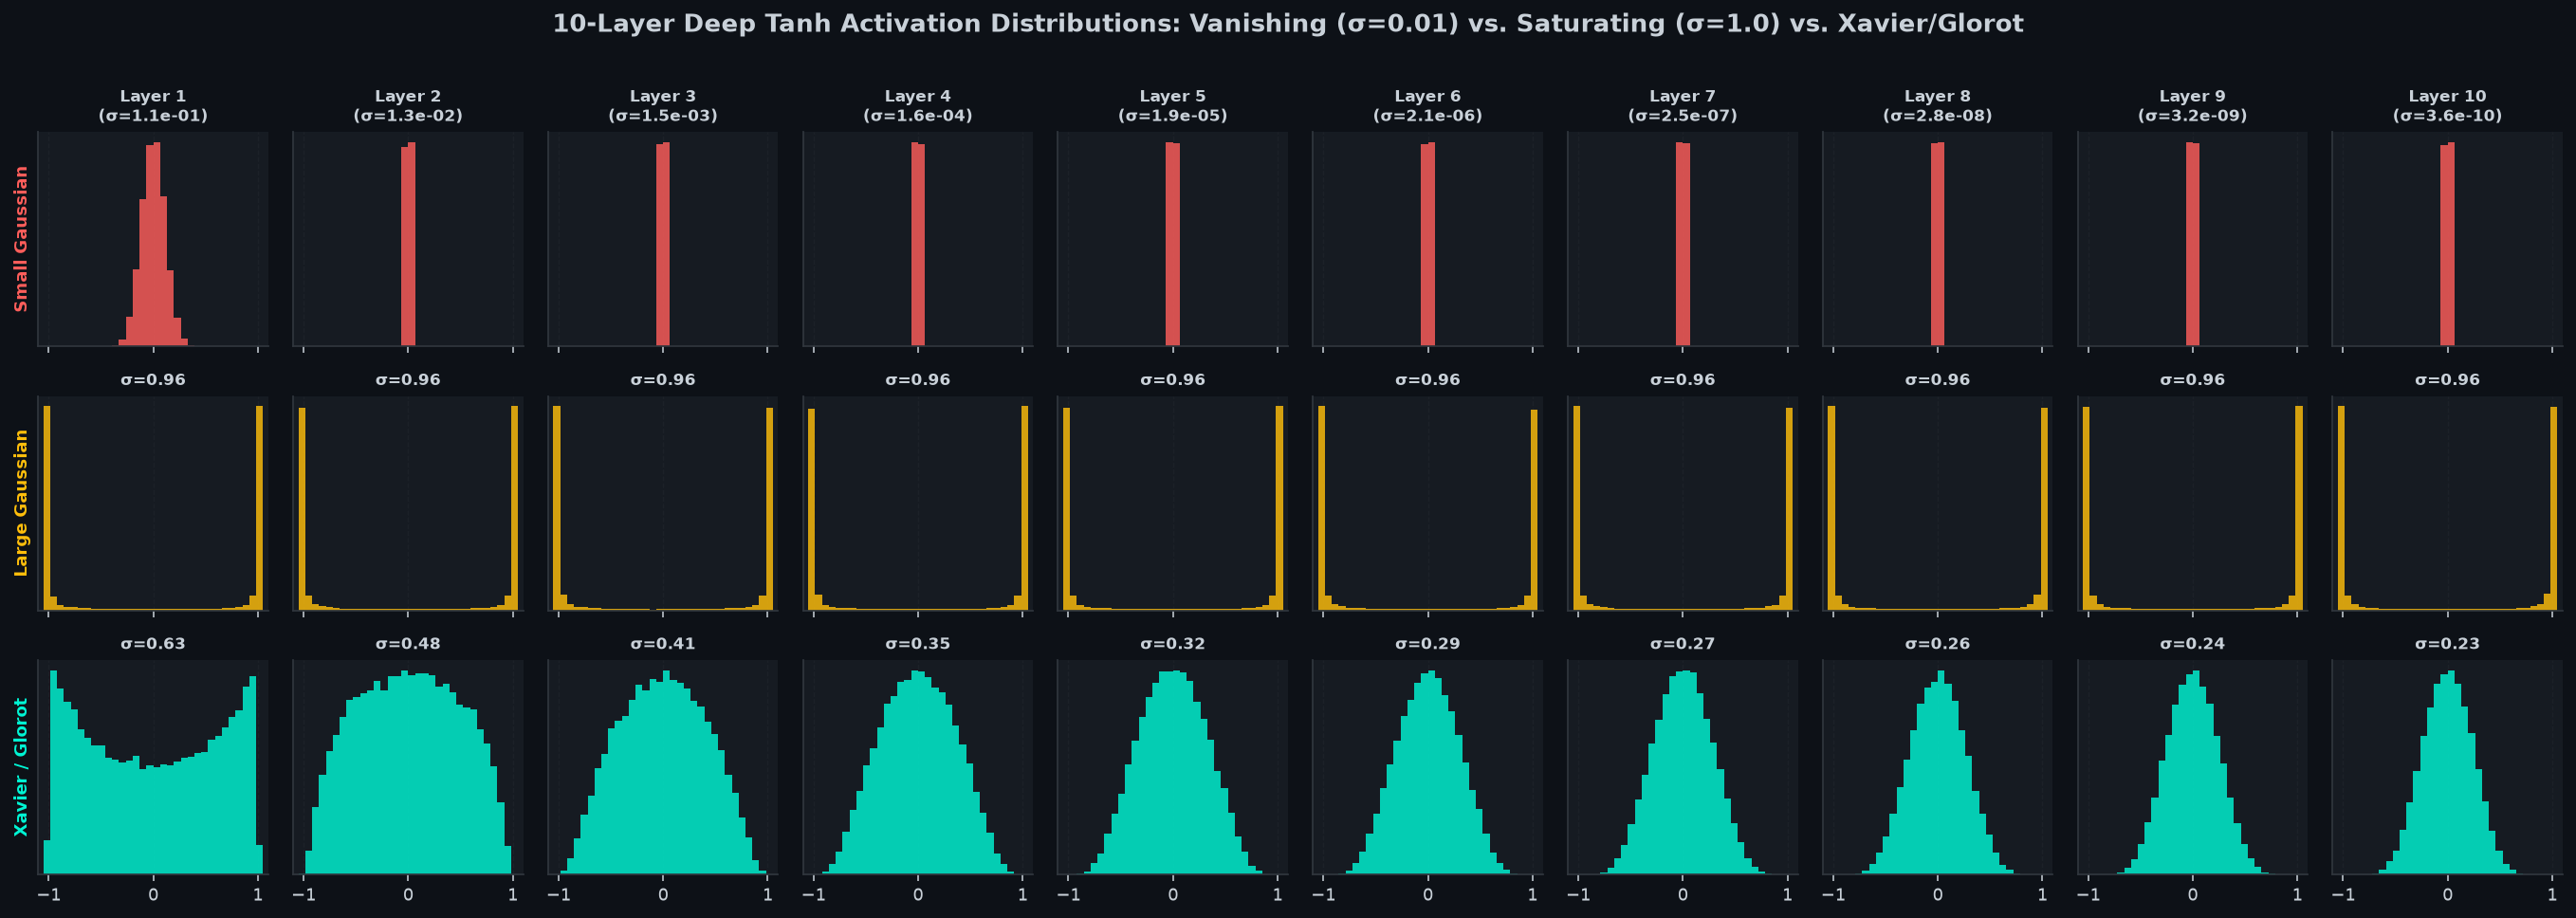

In [3]:
X_deep = rng.normal(0.0, 1.0, size=(350, 128))
layer_architecture = [128] * 11 + [3]  # 10 hidden layers of width 128

init_configs = [
    (r"Small Gaussian ($\sigma = 0.01$: Vanishing)", "small_normal", CORAL),
    (r"Large Gaussian ($\sigma = 1.00$: Saturating at $\pm 1$)", "large_normal", AMBER),
    (r"Xavier / Glorot ($\sigma = \sqrt{2/(d_{\mathrm{in}}+d_{\mathrm{out}})}$: Stable)", "xavier", CYAN),
]

fig, axes = plt.subplots(3, 10, figsize=(19.5, 6.8), sharex=True, sharey=False)

for row_idx, (row_title, mode_name, col_hist) in enumerate(init_configs):
    net_10 = NumPyDeepMLPScratch(
        layer_dims=layer_architecture,
        hidden_activation="tanh",
        init_mode=mode_name,
        random_state=100 + row_idx,
    )
    _ = net_10.forward(X_deep, training=False)
    stds_row = []

    for l_idx in range(10):
        ax = axes[row_idx, l_idx]
        act_l = net_10.A_cache[l_idx + 1].ravel()
        std_l = float(np.std(act_l))
        stds_row.append(std_l)

        ax.hist(act_l, bins=32, range=(-1.05, 1.05), density=True, color=col_hist, alpha=0.82, edgecolor="none")
        ax.set_xlim(-1.1, 1.1)
        ax.set_yticks([])
        if row_idx == 0:
            ax.set_title(f"Layer {l_idx+1}\n(σ={std_l:.1e})", fontsize=8.8)
        else:
            ax.set_title(f"σ={std_l:.2f}", fontsize=8.8)
        if row_idx == 2:
            ax.set_xticks([-1, 0, 1])
        if l_idx == 0:
            ax.set_ylabel(row_title.split("(")[0].strip(), fontsize=9.5, fontweight="bold", color=col_hist)

    print(f"{row_title:<58} | Layer 1 Std = {stds_row[0]:.4e} | Layer 5 Std = {stds_row[4]:.4e} | Layer 10 Std = {stds_row[9]:.4e}")

fig.suptitle(
    "10-Layer Deep Tanh Activation Distributions: Vanishing (σ=0.01) vs. Saturating (σ=1.0) vs. Xavier/Glorot",
    fontsize=13.5,
    fontweight="bold",
    y=1.01,
)
fig.tight_layout()
save_fig(fig, assets_dir / "02_weight_init_activation_distributions.png")
plt.show()

## 3. Optimization Benchmark: Escaping a Saddle-Point Surface & Training Raw PyTorch Kernels (`03_optimizer_trajectories_saddle_point.png`)

First, we trace Vanilla SGD, Momentum, RMSProp, and Adam on a 2D non-convex **Monkey/Hyperbolic Saddle-Ravine Landscape**:
$$f(w_1, w_2) = 0.55 w_1^2 - 0.85 w_2^2 + 0.22 w_2^4 + 0.08 w_1 w_2 + 1.5$$
initialized just off the flat saddle point at $\mathbf{w}^{(0)} = [2.2, 0.015]^\top$ where $\partial f / \partial w_2 \approx 0$.
Second, we train our `RawPyTorchMLP` (using custom `LinearFunction`, `GELUFunction`, and `StableCrossEntropyFunction`) with all 4 custom `RawPyTorchOptimizer` algorithms!

RawPyTorchMLP [Vanilla SGD (lr=0.15)         ] | Final Loss = 0.1564 | Spiral Accuracy = 97.33%
RawPyTorchMLP [SGD + Momentum (lr=0.08)      ] | Final Loss = 0.0065 | Spiral Accuracy = 100.00%
RawPyTorchMLP [RMSProp (lr=0.015)            ] | Final Loss = 0.0024 | Spiral Accuracy = 100.00%
RawPyTorchMLP [Adam (lr=0.025)               ] | Final Loss = 0.0004 | Spiral Accuracy = 100.00%


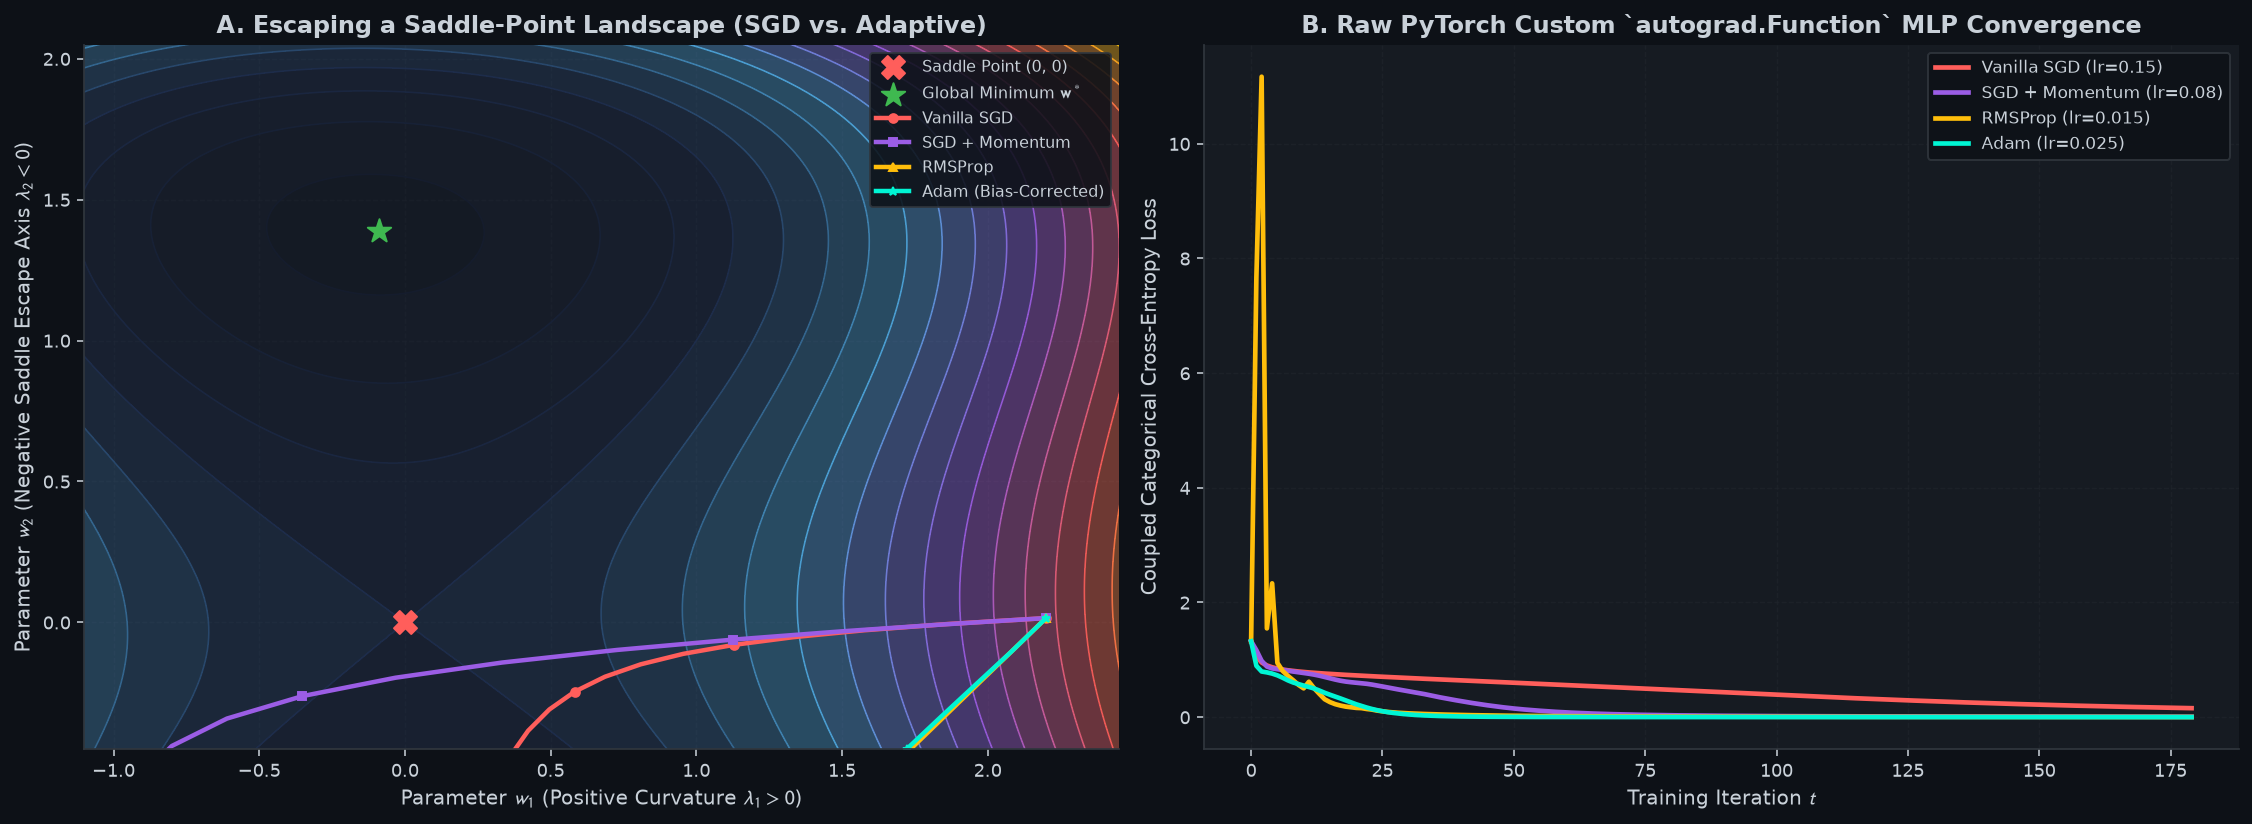

In [4]:
def saddle_loss_and_grad(w: np.ndarray) -> tuple[float, np.ndarray]:
    w1, w2 = w[0], w[1]
    val = 0.55 * (w1 ** 2) - 0.85 * (w2 ** 2) + 0.22 * (w2 ** 4) + 0.08 * w1 * w2 + 1.5
    gw1 = 1.10 * w1 + 0.08 * w2
    gw2 = -1.70 * w2 + 0.88 * (w2 ** 3) + 0.08 * w1
    return float(val), np.array([gw1, gw2], dtype=np.float64)


def run_2d_optimizer(opt_kind: str, lr: float, steps: int = 55) -> np.ndarray:
    w = np.array([2.2, 0.015], dtype=np.float64)
    m = np.zeros(2, dtype=np.float64)
    v = np.zeros(2, dtype=np.float64)
    beta1, beta2, eps = 0.88, 0.99, 1e-8
    path = [w.copy()]

    for t in range(1, steps + 1):
        _, g = saddle_loss_and_grad(w)
        if opt_kind == "sgd":
            w = w - lr * g
        elif opt_kind == "momentum":
            m = beta1 * m + g
            w = w - lr * m
        elif opt_kind == "rmsprop":
            v = beta2 * v + (1.0 - beta2) * (g ** 2)
            w = w - lr * g / (np.sqrt(v) + eps)
        elif opt_kind == "adam":
            m = beta1 * m + (1.0 - beta1) * g
            v = beta2 * v + (1.0 - beta2) * (g ** 2)
            mh = m / (1.0 - beta1 ** t)
            vh = v / (1.0 - beta2 ** t)
            w = w - lr * mh / (np.sqrt(vh) + eps)
        path.append(w.copy())
    return np.array(path)


paths_2d = {
    "Vanilla SGD": (run_2d_optimizer("sgd", lr=0.14), CORAL, "o"),
    "SGD + Momentum": (run_2d_optimizer("momentum", lr=0.055), PURPLE, "s"),
    "RMSProp": (run_2d_optimizer("rmsprop", lr=0.08), AMBER, "^"),
    "Adam (Bias-Corrected)": (run_2d_optimizer("adam", lr=0.12), CYAN, "*"),
}

# Train RawPyTorchMLP on the 3-Class Spiral with all 4 custom RawPyTorchOptimizer algorithms
X_sp_pt = torch.tensor(X_spiral, dtype=torch.float64)
y_sp_pt = torch.tensor(y_spiral, dtype=torch.long)

pt_opt_configs = [
    (r"Vanilla SGD (lr=0.15)", "sgd", 0.15, CORAL),
    (r"SGD + Momentum (lr=0.08)", "momentum", 0.08, PURPLE),
    (r"RMSProp (lr=0.015)", "rmsprop", 0.015, AMBER),
    (r"Adam (lr=0.025)", "adam", 0.025, CYAN),
]

pt_loss_curves = {}
for label_o, o_type, lr_o, _ in pt_opt_configs:
    net_pt = RawPyTorchMLP(layer_dims=[2, 32, 24, 3], activation="gelu", seed=42)
    opt_pt = RawPyTorchOptimizer(net_pt.parameters, opt_type=o_type, lr=lr_o)
    curve = []
    for _ in range(180):
        opt_pt.zero_grad()
        l_val = net_pt.loss(X_sp_pt, y_sp_pt)
        l_val.backward()
        opt_pt.step()
        curve.append(float(l_val.item()))
    pt_loss_curves[label_o] = curve
    with torch.no_grad():
        preds_pt = torch.argmax(net_pt.forward(X_sp_pt), dim=1).numpy()
        acc_pt = float(np.mean(preds_pt == y_spiral))
    print(f"RawPyTorchMLP [{label_o:<30}] | Final Loss = {curve[-1]:.4f} | Spiral Accuracy = {acc_pt*100:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.2, 6.0))

# Panel A: 2D Saddle-Point Escape Trajectories
w1_s = np.linspace(-1.2, 2.5, 140)
w2_s = np.linspace(-0.6, 2.2, 140)
W1_sg, W2_sg = np.meshgrid(w1_s, w2_s)
J_sad = 0.55 * (W1_sg ** 2) - 0.85 * (W2_sg ** 2) + 0.22 * (W2_sg ** 4) + 0.08 * W1_sg * W2_sg + 1.5

ax1.contourf(W1_sg, W2_sg, J_sad, levels=26, cmap=CMAP_SURFACE, alpha=0.38)
ax1.contour(W1_sg, W2_sg, J_sad, levels=26, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.82)
ax1.scatter([0.0], [0.0], color=CORAL, s=140, marker="X", zorder=8, label="Saddle Point (0, 0)")
ax1.scatter([-0.09], [1.39], color=EMERALD, s=160, marker="*", zorder=8, label=r"Global Minimum $\mathbf{w}^*$")

for name_p, (tr_p, col_p, mk_p) in paths_2d.items():
    ax1.plot(tr_p[:, 0], tr_p[:, 1], color=col_p, linewidth=2.3, marker=mk_p, markersize=4.5, markevery=4, label=name_p)

ax1.set_xlim(-1.1, 2.45)
ax1.set_ylim(-0.45, 2.05)
ax1.set_xlabel(r"Parameter $w_1$ (Positive Curvature $\lambda_1 > 0$)")
ax1.set_ylabel(r"Parameter $w_2$ (Negative Saddle Escape Axis $\lambda_2 < 0$)")
ax1.set_title("A. Escaping a Saddle-Point Landscape (SGD vs. Adaptive)")
ax1.legend(loc="upper right", fontsize=8.4)

# Panel B: Raw PyTorch Custom autograd.Function Training Curves
for label_o, _, _, col_o in pt_opt_configs:
    ax2.plot(pt_loss_curves[label_o], color=col_o, linewidth=2.4, label=label_o)

ax2.set_xlabel("Training Iteration $t$")
ax2.set_ylabel("Coupled Categorical Cross-Entropy Loss")
ax2.set_title("B. Raw PyTorch Custom `autograd.Function` MLP Convergence")
ax2.legend(loc="upper right", fontsize=8.6)

fig.tight_layout()
save_fig(fig, assets_dir / "03_optimizer_trajectories_saddle_point.png")
plt.show()